In [3]:
%pip install langgraph

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [langgraph]
Note: you may need to restart the kernel to use updated packages.


In [5]:
%pip install langgraph-checkpoint-sqlite

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [langgraph-checkpoint-sqlite]
Note: you may need to restart the kernel to use updated packages.


In [6]:
# Imports and environment first, as always

import os
import random
import requests
from typing import Annotated
from typing_extensions import TypedDict
from dotenv import load_dotenv
from IPython.display import Image, display
import gradio as gr
from langchain_openai import ChatOpenAI
# from langchain_community.tools import GoogleSerperRun
# from langchain_community.utilities import GoogleSerperAPIWrapper
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
from langgraph.checkpoint.sqlite import SqliteSaver

load_dotenv(override=True)

True

In [7]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

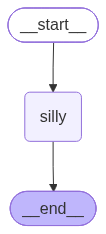

In [8]:
nouns = ["Cabbages", "Unicorns", "Toasters", "Penguins", "Bananas", "Eels", "Pickles"]
adjectives = ["outrageous", "smelly", "pedantic", "existential", "sparkly", "haunted"]

def silly_node(state: State) -> dict:
    sentence = f"{random.choice(nouns)} are {random.choice(adjectives)}"
    return {"messages": [{"role": "assistant", "content": sentence}]}

builder = StateGraph(State)
builder.add_node("silly", silly_node)
builder.add_edge(START, "silly")
builder.add_edge("silly", END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [10]:
result = graph.invoke({"messages": [{"role": "user", "content": "say something"}]})
print(result["messages"][-1].content)

Eels are haunted


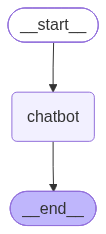

In [11]:
llm = ChatOpenAI(model="gpt-5.4-mini")

def chatbot_node(state: State) -> dict:
    return {"messages": [llm.invoke(state["messages"])]}

builder = StateGraph(State)
builder.add_node("chatbot", chatbot_node)
builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [12]:
result = graph.invoke({"messages": [{"role": "user", "content": "What is a directed graph, in one sentence?"}]})
print(result["messages"][-1].content)

A directed graph is a set of nodes connected by edges that have a direction, meaning each edge goes from one node to another.


In [13]:
# search = GoogleSerperRun(api_wrapper=GoogleSerperAPIWrapper())

@tool
def send_push_notification(text: str) -> str:
    """Send a short push notification to the user's phone."""
    # requests.post(
    #     "https://api.pushover.net/1/messages.json",
    #     data={"token": os.getenv("PUSHOVER_TOKEN"), "user": os.getenv("PUSHOVER_USER"), "message": text},
    # )
    return "Notification sent"

# tools = [search, send_push_notification]
tools = [send_push_notification]
llm_with_tools = llm.bind_tools(tools)

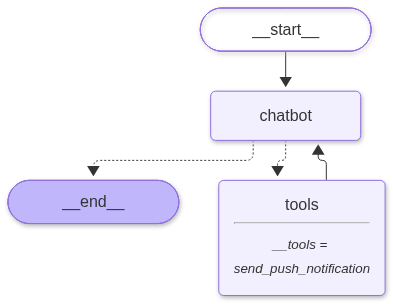

In [14]:
def chatbot_node(state: State) -> dict:
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)

builder.add_node("chatbot", chatbot_node)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition)
builder.add_edge("tools", "chatbot")

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [15]:
result = graph.invoke({"messages": [{"role": "user", "content": "Use your search tool to tell me the ingredients in banoffee pie and send me a push notification."}]})
print(result["messages"][-1].content)

Banoffee pie is typically made with:

- Digestive biscuits or graham crackers
- Butter
- Sweetened condensed milk or dulce de leche
- Bananas
- Whipped cream

Optional additions can include chocolate shavings, cocoa powder, or coffee.


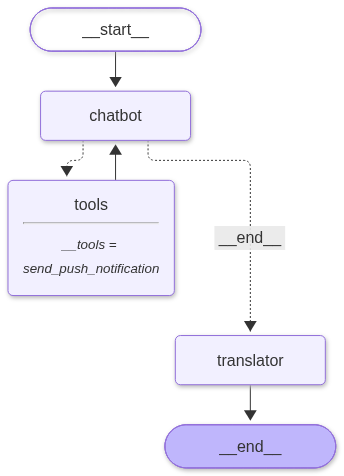

In [16]:
class State(TypedDict):
    messages: Annotated[list, add_messages]
    spanish: str

def translator_node(state: State) -> dict:
    last = state["messages"][-1].content
    prompt = f"Translate this into Spanish, replying with the translation only:\n\n{last}"
    return {"spanish": llm.invoke(prompt).content}

builder = StateGraph(State)

builder.add_node("chatbot", chatbot_node)
builder.add_node("tools", ToolNode(tools))
builder.add_node("translator", translator_node)

builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition, {"tools": "tools", END:"translator"})
builder.add_edge("tools", "chatbot")
builder.add_edge("translator", END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [17]:
result = graph.invoke({"messages": [{"role": "user", "content": "In one sentence, what is special about a banana?"}]})
print(result["messages"][-1].content)
print(result["spanish"])

A banana is special because it’s technically a berry, while strawberries are not.
Un plátano es especial porque técnicamente es una baya, mientras que las fresas no lo son.


In [18]:
memory = MemorySaver()

builder = StateGraph(State)
builder.add_node("chatbot", chatbot_node)
builder.add_node("tools", ToolNode(tools))
builder.add_node("translator", translator_node)
builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition, {"tools": "tools", END: "translator"})
builder.add_edge("translator", END)
builder.add_edge("tools", "chatbot")
graph = builder.compile(checkpointer=memory)


config = {"configurable": {"thread_id": "conversation-1"}}
graph.invoke({"messages": [{"role": "user", "content": "Hi, my name is Ed."}]}, config)
second = graph.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config)
print(second["messages"][-1].content)
print(second["spanish"])

Your name is Ed.
Tu nombre es Ed.


In [19]:
with SqliteSaver.from_conn_string("memory.db") as sql_memory:
    durable_graph = builder.compile(checkpointer=sql_memory)
    sql_config = {"configurable": {"thread_id": "conversation-2"}}
    durable_graph.invoke({"messages": [{"role": "user", "content": "Remember that my favorite color is orange."}]}, sql_config)
    reply = durable_graph.invoke({"messages": [{"role": "user", "content": "What is my favorite color?"}]}, sql_config)
    print(reply["messages"][-1].content)
    print(reply["spanish"])

Your favorite color is orange.
Tu color favorito es naranja.


In [20]:
snapshot = graph.get_state(config)
messages = snapshot.values["messages"]
print("Messages stored so far:", len(messages))

for message in messages:
    print(message.content)

history = list(graph.get_state_history(config))
print("Number of saved checkpoints:", len(history))

Messages stored so far: 4
Hi, my name is Ed.
Hi Ed — nice to meet you. How can I help?
What is my name?
Your name is Ed.
Number of saved checkpoints: 8


In [21]:
for h in reversed(history):            # history is newest first; reversed reads as a story
      m = h.metadata
      queued = ", ".join(t.name for t in h.tasks) or "(run complete)"
      print(f"step {m['step']:>2}  {m['source']:<5}  messages={len(h.values.get('messages', []))}  about to run: {queued}")

step -1  input  messages=0  about to run: __start__
step  0  loop   messages=1  about to run: chatbot
step  1  loop   messages=2  about to run: translator
step  2  loop   messages=2  about to run: (run complete)
step  3  input  messages=2  about to run: __start__
step  4  loop   messages=3  about to run: chatbot
step  5  loop   messages=4  about to run: translator
step  6  loop   messages=4  about to run: (run complete)


In [ ]:
# Time travel: take a checkpoint from earlier and resume the graph from that exact moment
earlier = history[len(history) // 2]
# earlier = history[-1]
print("A checkpoint from earlier held", len(earlier.values["messages"]), "messages")

replay_config = {"configurable": {"thread_id": "conversation-1",
                                  "checkpoint_id": earlier.config["configurable"]["checkpoint_id"]}}
resumed = graph.invoke(None, replay_config)
print("Resumed from the past; the graph now holds", len(resumed["messages"]), "messages")

again = graph.invoke({"messages": [{"role": "user", "content": "What do you know about me?"}]}, replay_config)
print(again["messages"][-1].content)
print(again["spanish"])

A checkpoint from earlier held 0 messages
Resumed from the past; the graph now holds 2 messages
I only know what you’ve shared in this conversation:

- You asked, “What do you know about me?”
- I don’t have access to your identity, contacts, location, or private data unless you explicitly share it here.
- I also don’t retain personal memory across chats unless a system specifically provides it.

If you want, I can help infer a little about your preferences or style from how you write here.
Solo sé lo que has compartido en esta conversación:

- Preguntaste: “¿Qué sabes de mí?”
- No tengo acceso a tu identidad, contactos, ubicación ni datos privados a menos que los compartas explícitamente aquí.
- Tampoco conservo memoria personal entre chats a menos que un sistema me la proporcione específicamente.

Si quieres, puedo ayudarte a inferir un poco sobre tus preferencias o tu estilo a partir de cómo escribes aquí.


In [ ]:
def chat(user_input: str, history):
    config = {"configurable": {"thread_id": "gradio-session4"}}
    result = graph.invoke({"messages": [{"role": "user", "content": user_input}]}, config)
    return f"{result['messages'][-1].content}\n\n*{result['spanish']}*"

gr.ChatInterface(chat).launch()